In [3]:
import sys
from pathlib import Path

project_root = Path().resolve().parent  # Goes from notebooks/ to project/
sys.path.insert(0, str(project_root))

In [4]:
from PIL import Image
from src.benchmarks import (
    MMVetDataset, MMEvalDataset, MathVerseDataset, MMStar, CharXiv
)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
# Benchmark configuration mapping
BENCHMARK_CLASSES = {
    "mmvet": MMVetDataset,
    "mathverse": MathVerseDataset,
    "mmstar": MMStar,
    "charxiv": CharXiv,
    "mmeval": MMEvalDataset,
}

BENCHMARK_DATASETS = {
    "mmvet": "whyu/mm-vet",
    "mathverse": "AI4Math/MathVerse",
    "mmstar": "Lin-Chen/MMStar",
    "charxiv": "princeton-nlp/charxiv",
    "mmeval": "darkyarding/MME",
}


In [6]:
def create_dataset(
    benchmark,
    field
):
    """Create benchmark dataset with specified transformation."""
    benchmark_lower = benchmark.lower()
    
    if benchmark_lower not in BENCHMARK_CLASSES:
        raise ValueError(
            f"Unsupported benchmark: {benchmark}. Please, add new benchmark to benchmarks.py"
            f"Available: {list(BENCHMARK_CLASSES.keys())}"
        )
    
    dataset_class = BENCHMARK_CLASSES[benchmark_lower]
    dataset_name = BENCHMARK_DATASETS[benchmark_lower]
    
    kwargs = {"dataset_name": dataset_name}
    kwargs["field"] = field
    
    return dataset_class(**kwargs)

In [7]:
image_sizes = []

for benchmark in BENCHMARK_CLASSES.keys():
    dataset = create_dataset(
            benchmark,
            field=0,
        )
    for i in dataset: 
        image = i["image"]
        image_sizes.append(image.size)

In [8]:
len(image_sizes)

9032

In [9]:
# Convert to DataFrame for easier analysis
df = pd.DataFrame(image_sizes, columns=['width', 'height'])

# Calculate derived features
df['total_pixels'] = df['width'] * df['height']
df['aspect_ratio'] = df['width'] / df['height']

print("=" * 60)
print("IMAGE DIMENSIONS SUMMARY STATISTICS")
print("=" * 60)
print(df.describe())
print("\n" + "=" * 60)
print("ASPECT RATIO STATISTICS")
print("=" * 60)
print(df['aspect_ratio'].describe())

IMAGE DIMENSIONS SUMMARY STATISTICS
             width       height  total_pixels  aspect_ratio
count  9032.000000  9032.000000  9.032000e+03   9032.000000
mean    659.742139   541.609942  4.926190e+05      1.379873
std     416.711131   394.372108  8.799073e+05      0.650280
min      63.000000    29.000000  4.410000e+03      0.326471
25%     376.000000   278.500000  1.063200e+05      0.994536
50%     576.000000   465.000000  2.732360e+05      1.316069
75%     845.000000   684.000000  5.641525e+05      1.553516
max    6840.000000  4438.000000  2.427516e+07     17.655172

ASPECT RATIO STATISTICS
count    9032.000000
mean        1.379873
std         0.650280
min         0.326471
25%         0.994536
50%         1.316069
75%         1.553516
max        17.655172
Name: aspect_ratio, dtype: float64


/tmp/ipykernel_1867230/1154695609.py:42: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1, 2].boxplot(box_data, labels=['Width', 'Height'])


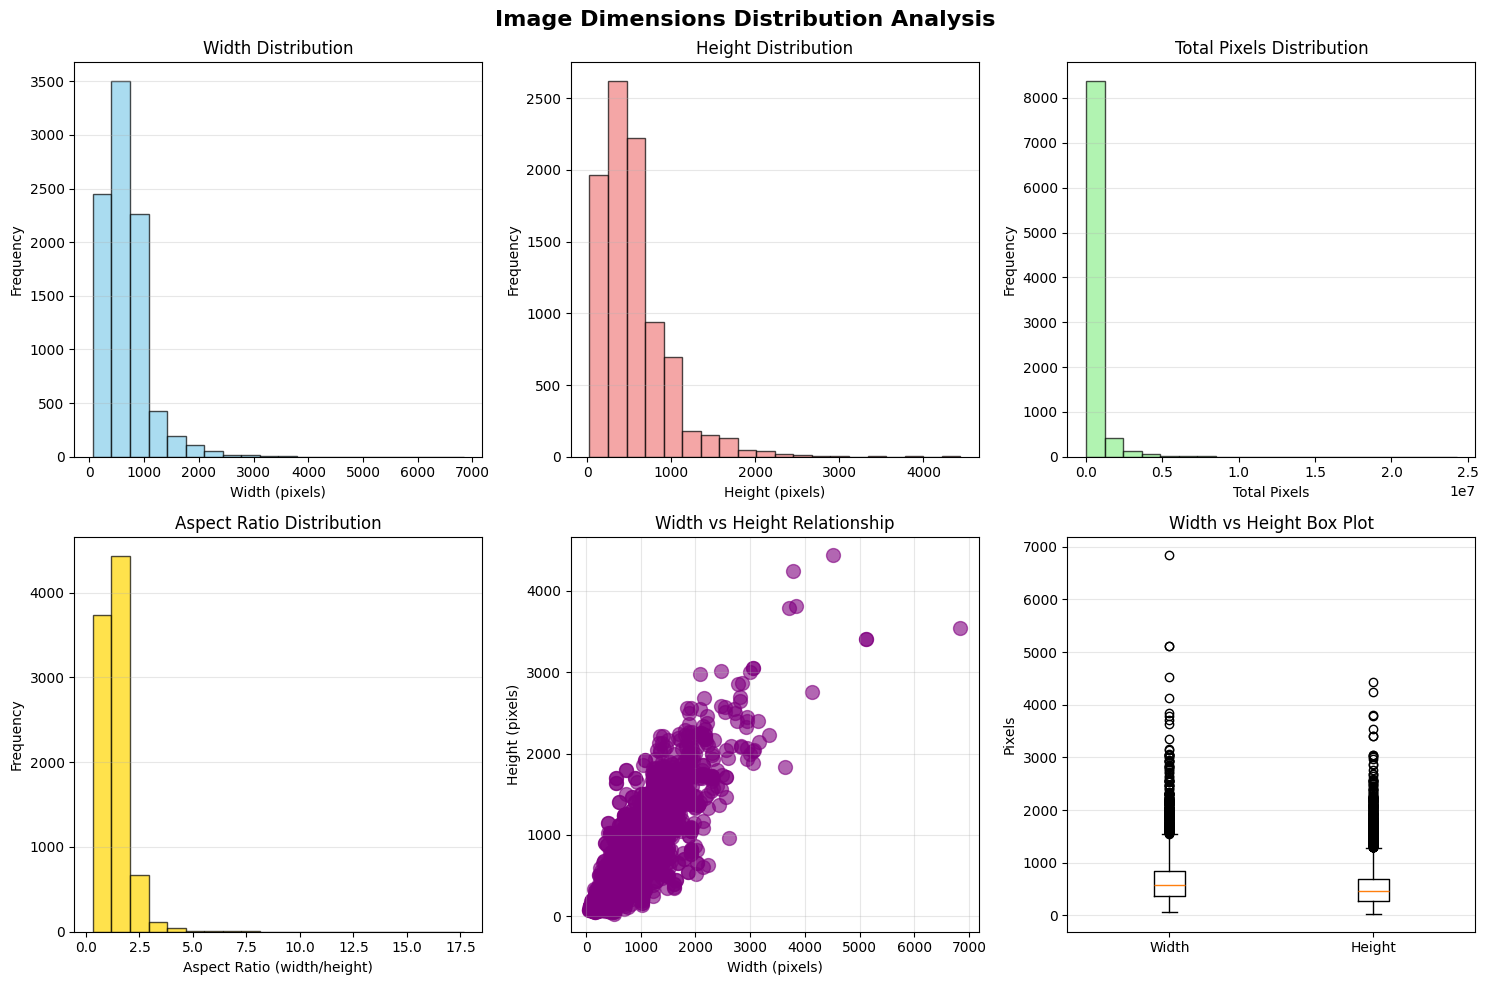

In [10]:
# Create comprehensive visualization
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Image Dimensions Distribution Analysis', fontsize=16, fontweight='bold')

# 1. Width Distribution
axes[0, 0].hist(df['width'], bins=20, color='skyblue', edgecolor='black', alpha=0.7)
axes[0, 0].set_xlabel('Width (pixels)')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Width Distribution')
axes[0, 0].grid(axis='y', alpha=0.3)

# 2. Height Distribution
axes[0, 1].hist(df['height'], bins=20, color='lightcoral', edgecolor='black', alpha=0.7)
axes[0, 1].set_xlabel('Height (pixels)')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title('Height Distribution')
axes[0, 1].grid(axis='y', alpha=0.3)

# 3. Total Pixels Distribution
axes[0, 2].hist(df['total_pixels'], bins=20, color='lightgreen', edgecolor='black', alpha=0.7)
axes[0, 2].set_xlabel('Total Pixels')
axes[0, 2].set_ylabel('Frequency')
axes[0, 2].set_title('Total Pixels Distribution')
axes[0, 2].grid(axis='y', alpha=0.3)

# 4. Aspect Ratio Distribution
axes[1, 0].hist(df['aspect_ratio'], bins=20, color='gold', edgecolor='black', alpha=0.7)
axes[1, 0].set_xlabel('Aspect Ratio (width/height)')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].set_title('Aspect Ratio Distribution')
axes[1, 0].grid(axis='y', alpha=0.3)

# 5. Width vs Height Scatter
axes[1, 1].scatter(df['width'], df['height'], alpha=0.6, s=100, color='purple')
axes[1, 1].set_xlabel('Width (pixels)')
axes[1, 1].set_ylabel('Height (pixels)')
axes[1, 1].set_title('Width vs Height Relationship')
axes[1, 1].grid(alpha=0.3)

# 6. Box plots for Width and Height
box_data = [df['width'], df['height']]
axes[1, 2].boxplot(box_data, labels=['Width', 'Height'])
axes[1, 2].set_ylabel('Pixels')
axes[1, 2].set_title('Width vs Height Box Plot')
axes[1, 2].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [11]:
# Additional insights
print("\n" + "=" * 60)
print("ADDITIONAL INSIGHTS")
print("=" * 60)
print(f"Min total pixels: {df['total_pixels'].min():,.0f}")
print(f"Max total pixels: {df['total_pixels'].max():,.0f}")
print(f"Mean total pixels: {df['total_pixels'].mean():,.0f}")
print(f"\nMost common aspect ratio: {df['aspect_ratio'].mode()[0]:.2f}")
print(f"Aspect ratio range: {df['aspect_ratio'].min():.2f} to {df['aspect_ratio'].max():.2f}")

# Identify outliers using IQR method
Q1_width = df['width'].quantile(0.25)
Q3_width = df['width'].quantile(0.75)
IQR_width = Q3_width - Q1_width
outliers_width = df[(df['width'] < Q1_width - 1.5*IQR_width) | (df['width'] > Q3_width + 1.5*IQR_width)]

print(f"\nPotential width outliers: {len(outliers_width)} images")
if len(outliers_width) > 0:
    print(outliers_width)


ADDITIONAL INSIGHTS
Min total pixels: 4,410
Max total pixels: 24,275,160
Mean total pixels: 492,619

Most common aspect ratio: 1.33
Aspect ratio range: 0.33 to 17.66

Potential width outliers: 285 images
      width  height  total_pixels  aspect_ratio
21     5119    3413      17471147      1.499854
22     5119    3413      17471147      1.499854
30     1920    1080       2073600      1.777778
48     2000    1342       2684000      1.490313
78     1600    1091       1745600      1.466544
...     ...     ...           ...           ...
7621   1718    1722       2958396      0.997677
7626   2306    1716       3957096      1.343823
7627   2306    1716       3957096      1.343823
8232   3048    3048       9290304      1.000000
8233   3048    3048       9290304      1.000000

[285 rows x 4 columns]


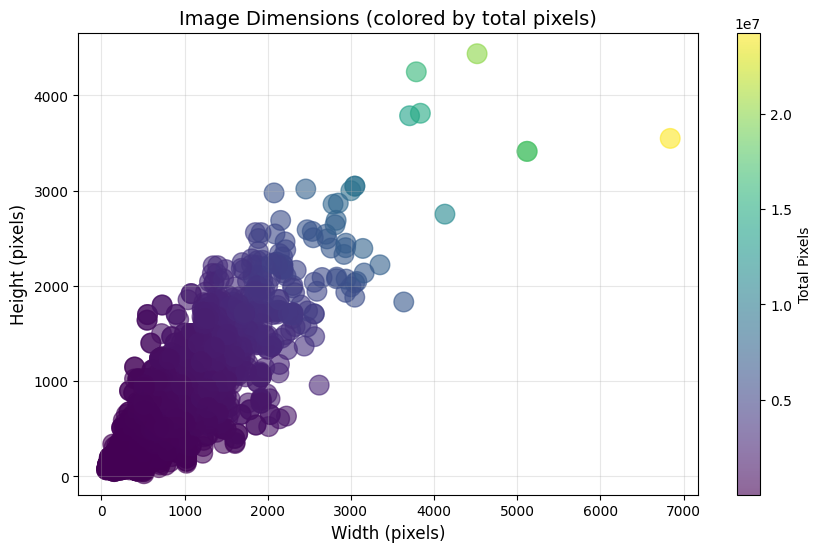

 Metric       Width      Height
    Min   63.000000   29.000000
    Max 6840.000000 4438.000000
   Mean  659.742139  541.609942
 Median  576.000000  465.000000
Std Dev  416.711131  394.372108


In [12]:
# Create a heatmap of dimension combinations
fig, ax = plt.subplots(figsize=(10, 6))
df_sorted = df.sort_values('width')
scatter = ax.scatter(df['width'], df['height'], 
                     c=df['total_pixels'], 
                     s=200, 
                     alpha=0.6, 
                     cmap='viridis')
ax.set_xlabel('Width (pixels)', fontsize=12)
ax.set_ylabel('Height (pixels)', fontsize=12)
ax.set_title('Image Dimensions (colored by total pixels)', fontsize=14)
plt.colorbar(scatter, ax=ax, label='Total Pixels')
plt.grid(alpha=0.3)
plt.show()

# Summary table
summary = pd.DataFrame({
    'Metric': ['Min', 'Max', 'Mean', 'Median', 'Std Dev'],
    'Width': [df['width'].min(), df['width'].max(), df['width'].mean(), 
              df['width'].median(), df['width'].std()],
    'Height': [df['height'].min(), df['height'].max(), df['height'].mean(), 
               df['height'].median(), df['height'].std()],
})
print(summary.to_string(index=False))
